# IMPORT LIBRARIES

In [15]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


In [16]:
CHURN_PATH = "Churn_Modeling.csv"
FEEDBACK_PATH = "Customer_Feedback.csv"
ID_COL = "CustomerId"
TEXT_COL = "Feedback_Text"
RATING_COL = "Rating"
OUT_DIR = "outputs"
SEED = 42
os.makedirs(OUT_DIR, exist_ok=True)
print("config OK")

config OK


# LOAD DATA SETS AND EXPLORE

In [17]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

In [18]:
churn = pd.read_csv(CHURN_PATH)
fb = pd.read_csv(FEEDBACK_PATH)
print("1. loaded:", fb.shape, "| columns:", fb.columns.tolist())
assert TEXT_COL in fb.columns, f"{TEXT_COL} not in columns"
print("   churn shape:", churn.shape)
print("   missing values in feedback:\n", fb.isna().sum())

1. loaded: (19271, 7) | columns: ['CustomerId', 'Customer_Name', 'Customer_Location', 'Bank_Name', 'Feedback_Date', 'Rating', 'Feedback_Text']
   churn shape: (10000, 13)
   missing values in feedback:
 CustomerId            0
Customer_Name         2
Customer_Location     0
Bank_Name             0
Feedback_Date         0
Rating                0
Feedback_Text        90
dtype: int64


In [19]:
fb = fb.dropna(subset=[TEXT_COL]).reset_index(drop=True)
fb[TEXT_COL] = fb[TEXT_COL].astype(str)
fb["text_len_chars"] = fb[TEXT_COL].str.len()
fb["text_len_words"] = fb[TEXT_COL].str.split().str.len()
print("2. rows with text:", len(fb))
assert len(fb) > 0, "Feedback_Text is empty in this file"
print("   sample:", fb[TEXT_COL].head(3).tolist())

2. rows with text: 19181
   sample: ['Very easy to use to view statements and make online payments. Your representatives have been courteous and helpful when I have called with a problem. And when there have been questionable charges on my account I have been contacted immediately. I would definitely recommend Merrick Bank to other family members and friends!', "Merrick Bank has always been good to me for business. I can rely on Merrick Bank to make sure I have a great Banking experience. Merrick also rewards me with credit increases when they see that I have been credit responsible customer. I'm pleased with their service. I would recommend Merrick Bank to anyone who's also looking to build their credit.", 'Times are tough for everyone and I have worked very hard to get my credit restored. Due to BOA antics I had to file for bankruptcy twice in 6 months and both times I asked to withdraw and the judge did so and recused both. However, I have written to bureaus several times for it to 

In [5]:
fb = fb.dropna(subset=[TEXT_COL]).drop_duplicates().reset_index(drop=True)
fb[TEXT_COL] = fb[TEXT_COL].astype(str)
fb["text_len_chars"] = fb[TEXT_COL].str.len()
fb["text_len_words"] = fb[TEXT_COL].str.split().str.len()
print(fb[["text_len_chars", "text_len_words"]].describe())

       text_len_chars  text_len_words
count    19181.000000    19181.000000
mean       549.631458      102.784943
std        208.317290       39.858633
min          6.000000        1.000000
25%        379.000000       70.000000
50%        552.000000      103.000000
75%        711.000000      133.000000
max       1854.000000      320.000000


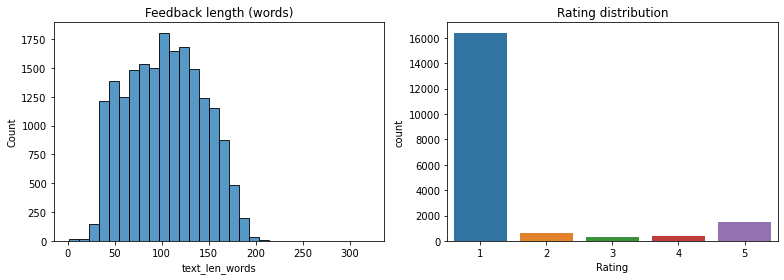

In [20]:
fig, ax = plt.subplots(1, 2 if RATING_COL else 1, figsize=(11, 4))
ax = np.atleast_1d(ax)
sns.histplot(fb["text_len_words"], bins=30, ax=ax[0]).set_title("Feedback length (words)")
if RATING_COL:
    sns.countplot(x=fb[RATING_COL], ax=ax[1]).set_title("Rating distribution")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_eda.png", dpi=150); plt.show()

# CLEANING

In [21]:
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [22]:
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words("english")) - {"no", "not", "nor", "never", "against"}

In [23]:
def clean_text(t):
    t = re.sub(r"[^a-z\s]", " ", t.lower())
    return " ".join(lemmatizer.lemmatize(w) for w in t.split() if w not in STOP and len(w) > 1)

In [25]:
fb["clean_text"] = fb[TEXT_COL].apply(clean_text)
print("3. rows with non-empty clean_text:", (fb["clean_text"].str.len() > 0).sum())
fb = fb[fb["clean_text"].str.len() > 0].reset_index(drop=True)
assert len(fb) > 0, "Cleaning removed everything - text may not be English"

3. rows with non-empty clean_text: 19181


# SENTIMENT LABELING

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

In [26]:
vader = SentimentIntensityAnalyzer()
fb["vader_polarity"] = fb[TEXT_COL].apply(lambda t: vader.polarity_scores(t)["compound"])
fb["textblob_polarity"] = fb[TEXT_COL].apply(lambda t: TextBlob(t).sentiment.polarity)
fb["sentiment"] = fb[RATING_COL].apply(lambda r: "Positive" if r >= 4 else "Neutral" if r == 3 else "Negative")
print("4. sentiment counts:\n", fb["sentiment"].value_counts())

4. sentiment counts:
 Negative    17021
Positive     1869
Neutral       291
Name: sentiment, dtype: int64


In [27]:
def vader_label(s):
    return "Positive" if s >= 0.05 else "Negative" if s <= -0.05 else "Neutral"

def rating_label(r):
    return "Positive" if r >= 4 else "Neutral" if r == 3 else "Negative"

if RATING_COL:
    fb["sentiment"] = fb[RATING_COL].apply(rating_label)
    agree = (fb["sentiment"] == fb["vader_polarity"].apply(vader_label)).mean()
    print(f"Rating-based labels vs VADER agreement: {agree:.1%}")
else:
    fb["sentiment"] = fb["vader_polarity"].apply(vader_label)
print(fb["sentiment"].value_counts())

Rating-based labels vs VADER agreement: 62.7%
Negative    17021
Positive     1869
Neutral       291
Name: sentiment, dtype: int64


# TEXT VECTORIZATION

In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split

In [29]:
print("Rows going into split:", len(fb))
counts = fb["sentiment"].value_counts()
strat = fb["sentiment"] if counts.min() >= 2 else None

Rows going into split: 19181


In [30]:
TEXT_COL = "Feedback_Text"   # use your actual column name
RATING_COL = "Rating"        # or None if there isn't one

In [31]:
X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(
    fb["clean_text"], fb["sentiment"], test_size=0.2, random_state=SEED, stratify=strat)

In [32]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True)
Xtr, Xte = tfidf.fit_transform(X_tr_txt), tfidf.transform(X_te_txt)
bow = CountVectorizer(min_df=2, max_features=20000)
Xtr_bow, Xte_bow = bow.fit_transform(X_tr_txt), bow.transform(X_te_txt)
print("TF-IDF shape:", Xtr.shape)

TF-IDF shape: (15344, 20000)


# MODELS AND EVALUATION

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

In [42]:
results = []
def evaluate(name, y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    results.append({"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
                    "Precision": p, "Recall": r, "F1": f})

In [43]:
models = {
    "LogReg (TF-IDF)": (LogisticRegression(max_iter=1000, class_weight="balanced"), Xtr, Xte),
    "LinearSVM (TF-IDF)": (LinearSVC(class_weight="balanced"), Xtr, Xte),
    "LogReg (BoW)": (LogisticRegression(max_iter=1000, class_weight="balanced"), Xtr_bow, Xte_bow),
}
fitted = {}
for name, (m, a, b) in models.items():
    m.fit(a, y_tr)
    evaluate(name, y_te, m.predict(b))
    fitted[name] = m

In [37]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

2026-10-11 22:13:29.533640: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-11 22:14:03.448877: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-11 22:14:45.237046: E tensorflow/compiler/xla/stream_executor/cuda/cuda_driver.cc:268] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


VOC-NOTICE: GPU memory for this assignment is capped at 1024MiB


In [47]:
classes = sorted(fb["sentiment"].unique())
cmap = {c: i for i, c in enumerate(classes)}

tok = Tokenizer(num_words=20000, oov_token="<OOV>")
tok.fit_on_texts(X_tr_txt)
maxlen = int(np.percentile(fb["clean_text"].str.split().str.len(), 95))

def seq(s):
    return pad_sequences(tok.texts_to_sequences(s), maxlen=maxlen)

ytr_i = y_tr.map(cmap).values
yte_i = y_te.map(cmap).values

lstm = Sequential([
    Embedding(20000, 32),
    LSTM(32),
    Dropout(0.3),
    Dense(len(classes), activation="softmax"),
])
lstm.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
lstm.fit(seq(X_tr_txt), ytr_i, validation_split=0.1, epochs=5, batch_size=128, verbose=2,
         callbacks=[EarlyStopping(patience=2, restore_best_weights=True)])

evaluate("LSTM", yte_i, lstm.predict(seq(X_te_txt)).argmax(1))

Epoch 1/5
108/108 - 8s - loss: 0.5380 - accuracy: 0.8761 - val_loss: 0.3437 - val_accuracy: 0.9016 - 8s/epoch - 77ms/step
Epoch 2/5
108/108 - 5s - loss: 0.2620 - accuracy: 0.9211 - val_loss: 0.1726 - val_accuracy: 0.9524 - 5s/epoch - 45ms/step
Epoch 3/5
108/108 - 5s - loss: 0.1666 - accuracy: 0.9582 - val_loss: 0.1409 - val_accuracy: 0.9603 - 5s/epoch - 45ms/step
Epoch 4/5
108/108 - 5s - loss: 0.1267 - accuracy: 0.9676 - val_loss: 0.1387 - val_accuracy: 0.9622 - 5s/epoch - 45ms/step
Epoch 5/5
108/108 - 5s - loss: 0.1039 - accuracy: 0.9736 - val_loss: 0.1402 - val_accuracy: 0.9603 - 5s/epoch - 45ms/step
120/120 [==============================] - 1s 5ms/step


=== Model comparison ===
              Model  Accuracy  Precision  Recall     F1
LinearSVM (TF-IDF)    0.9580     0.9501  0.9580 0.9518
   LogReg (TF-IDF)    0.9450     0.9450  0.9450 0.9449
              LSTM    0.9497     0.9340  0.9497 0.9415
      LogReg (BoW)    0.9273     0.9402  0.9273 0.9331

LogReg (TF-IDF) report:
               precision    recall  f1-score   support

    Negative       0.98      0.97      0.97      3405
     Neutral       0.22      0.19      0.20        58
    Positive       0.78      0.84      0.81       374

    accuracy                           0.95      3837
   macro avg       0.66      0.67      0.66      3837
weighted avg       0.95      0.95      0.94      3837



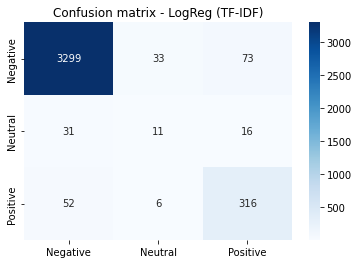

In [48]:
res_df = pd.DataFrame(results).round(4).sort_values("F1", ascending=False)
print("=== Model comparison ===\n", res_df.to_string(index=False))
res_df.to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)

best_name = "LogReg (TF-IDF)"
best = fitted[best_name]
print(f"\n{best_name} report:\n", classification_report(y_te, best.predict(Xte)))
labels = sorted(fb["sentiment"].unique())
sns.heatmap(confusion_matrix(y_te, best.predict(Xte), labels=labels), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.title(f"Confusion matrix - {best_name}")
plt.savefig(f"{OUT_DIR}/02_confusion.png", dpi=150); plt.show()

# MERGING WITH CHURN DATA

In [49]:
proba = best.predict_proba(tfidf.transform(fb["clean_text"]))
pc = {c: i for i, c in enumerate(best.classes_)}
fb["model_polarity"] = proba[:, pc["Positive"]] - proba[:, pc["Negative"]]
fb["pred_sentiment"] = best.predict(tfidf.transform(fb["clean_text"]))

agg = fb.groupby(ID_COL).agg(
    n_feedback=("sentiment", "size"),
    avg_vader_polarity=("vader_polarity", "mean"),
    avg_model_polarity=("model_polarity", "mean"),
    avg_text_words=("text_len_words", "mean"),
    pct_negative=("pred_sentiment", lambda s: (s == "Negative").mean()),
    pct_positive=("pred_sentiment", lambda s: (s == "Positive").mean()),
    avg_rating=(RATING_COL, "mean"),
    dominant_sentiment=("pred_sentiment", lambda s: s.mode().iloc[0]),
).reset_index()

unified = churn.merge(agg, on=ID_COL, how="left")
print(f"Customers with feedback: {unified['n_feedback'].notna().sum()} / {len(unified)}")
unified.to_csv(f"{OUT_DIR}/unified_churn_sentiment.csv", index=False)
unified.head()

Customers with feedback: 9957 / 10000


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,...,EstimatedSalary,Exited,n_feedback,avg_vader_polarity,avg_model_polarity,avg_text_words,pct_negative,pct_positive,avg_rating,dominant_sentiment
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,...,101348.88,1,1.0,0.8976,0.992283,52.0,0.0,1.0,5.0,Positive
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,...,112542.58,0,1.0,0.9774,0.995918,61.0,0.0,1.0,5.0,Positive
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,...,113931.57,1,1.0,0.9552,0.599184,115.0,0.0,1.0,4.0,Positive
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,...,93826.63,0,1.0,0.9885,0.969447,108.0,0.0,1.0,5.0,Positive
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,...,79084.10,0,1.0,0.9331,0.332984,145.0,0.0,1.0,5.0,Positive


# VISUALIZATIONS AND INSIGHTS

In [51]:
import matplotlib
from collections import Counter
from wordcloud import WordCloud

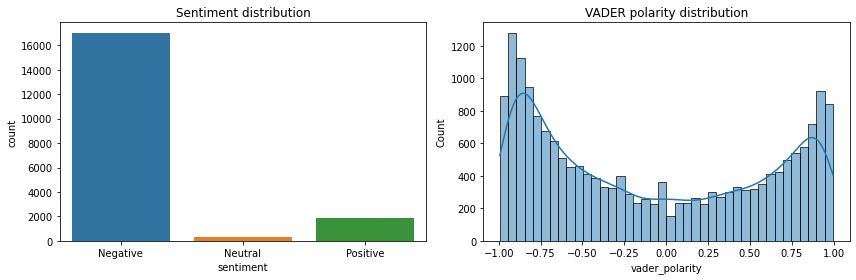

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="sentiment", data=fb, order=["Negative", "Neutral", "Positive"], ax=ax[0]).set_title("Sentiment distribution")
sns.histplot(fb["vader_polarity"], bins=40, kde=True, ax=ax[1]).set_title("VADER polarity distribution")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/03_sentiment_distribution.png", dpi=150); plt.show()

Word cloud failed for Positive (Only supported for TrueType fonts); showing top words instead
Word cloud failed for Neutral (Only supported for TrueType fonts); showing top words instead
Word cloud failed for Negative (Only supported for TrueType fonts); showing top words instead


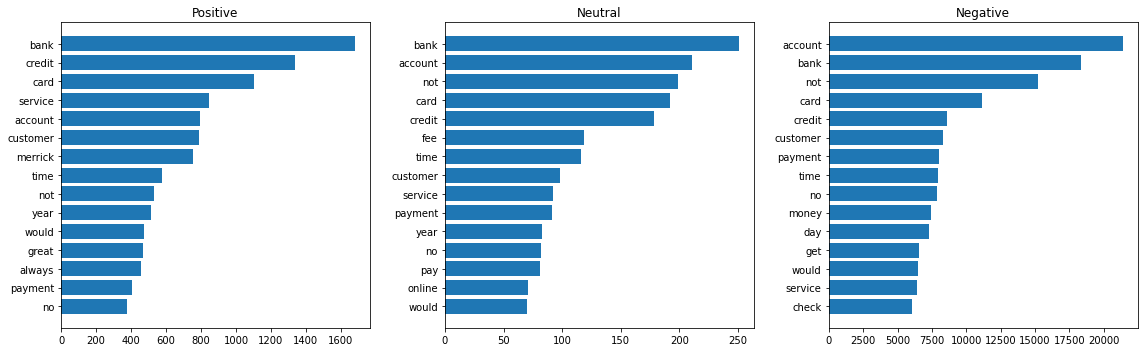

In [53]:
FONT = os.path.join(matplotlib.get_data_path(), "fonts", "ttf", "DejaVuSans.ttf")
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, s in zip(ax, ["Positive", "Neutral", "Negative"]):
    txt = " ".join(fb.loc[fb["sentiment"] == s, "clean_text"])
    if not txt.strip():
        a.axis("off"); continue
    try:
        wc = WordCloud(width=600, height=400, background_color="white", font_path=FONT).generate(txt)
        a.imshow(wc)
        a.axis("off")
    except Exception as e:
        # Fallback: top-15 words as a bar chart
        top = Counter(txt.split()).most_common(15)
        a.barh([w for w, _ in top][::-1], [c for _, c in top][::-1])
        print(f"Word cloud failed for {s} ({e}); showing top words instead")
    a.set_title(s)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_wordclouds.png", dpi=150); plt.show()

In [54]:
merged = unified.dropna(subset=["avg_model_polarity"])
sent_cols = ["avg_vader_polarity", "avg_model_polarity", "pct_negative", "pct_positive", "avg_rating"]
corr = merged[sent_cols + ["Exited"]].corr()["Exited"].drop("Exited")
print("Correlation with Exited:\n", corr.round(3))

Correlation with Exited:
 avg_vader_polarity    0.008
avg_model_polarity    0.010
pct_negative         -0.010
pct_positive          0.008
avg_rating            0.004
Name: Exited, dtype: float64


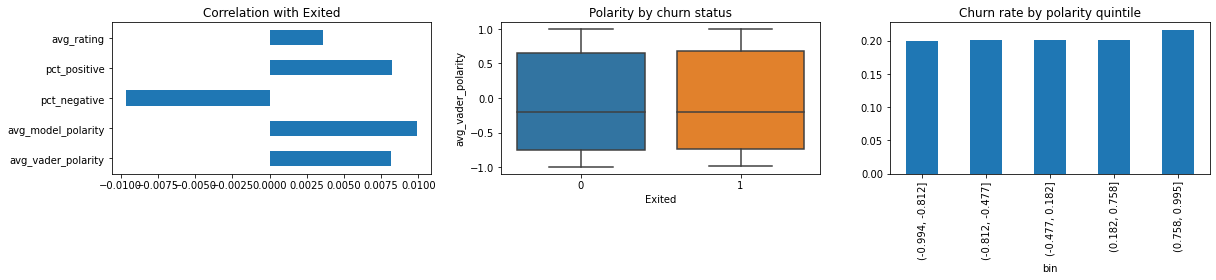

In [55]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
corr.plot.barh(ax=ax[0], title="Correlation with Exited")
sns.boxplot(x="Exited", y="avg_vader_polarity", data=merged, ax=ax[1]).set_title("Polarity by churn status")
merged.assign(bin=pd.qcut(merged["avg_vader_polarity"], 5, duplicates="drop")) \
      .groupby("bin")["Exited"].mean().plot(kind="bar", ax=ax[2], title="Churn rate by polarity quintile")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_sentiment_vs_churn.png", dpi=150); plt.show()